# Actividad 3. Búsqueda y consulta con pandas

In [ ]:
%pip install matplotlib

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('notas_bd2_capitulo3.csv')
df.head()

,ID_Estudiante,Grupo,Nota_Lab_Final
0,GS123-01,GS123,98.5
1,GS123-02,GS123,89.1
2,GS123-03,GS123,86.7
3,GS123-04,GS123,73.0
4,GS123-05,GS123,84.1


**Lookup**: se conoce el objetivo (GS124-05) y dónde buscarlo (columna ID_Estudiante). Consulta: identificar.

In [2]:
df.loc[df['ID_Estudiante'] == 'GS124-05']

,ID_Estudiante,Grupo,Nota_Lab_Final
14,GS124-05,GS124,74.4


**Locate**: se sabe qué se busca (la nota más baja) pero no en qué fila está. Target: extremo (mínimo).

In [3]:
df.loc[df['Nota_Lab_Final'].idxmin()]

ID_Estudiante     GS124-08
Grupo                GS124
Nota_Lab_Final        63.2
Name: 17, dtype: object

**Browse**: se conoce la ubicación (grupo GS124) pero no exactamente qué se busca; se examinan los registros en busca de patrones.

In [4]:
gs124 = df[df['Grupo'] == 'GS124']
gs124.sort_values('Nota_Lab_Final')

,ID_Estudiante,Grupo,Nota_Lab_Final
17,GS124-08,GS124,63.2
10,GS124-01,GS124,64.8
19,GS124-10,GS124,66.3
16,GS124-07,GS124,70.2
15,GS124-06,GS124,71.2
14,GS124-05,GS124,74.4
12,GS124-03,GS124,80.2
11,GS124-02,GS124,80.2
18,GS124-09,GS124,80.9
13,GS124-04,GS124,86.0


**Explore**: no se conoce ni el objetivo ni su ubicación; se parte de una vista general (resumir) para observar la distribución.

       Nota_Lab_Final
count       30.000000
mean        82.460000
std          9.107655
min         63.200000
25%         80.200000
50%         83.800000
75%         87.975000
max        100.000000


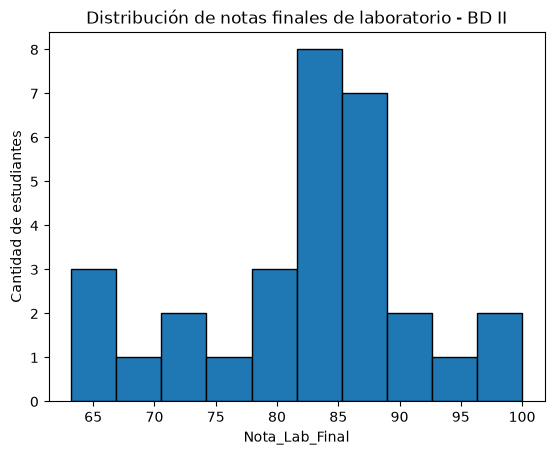

In [5]:
print(df.describe())

plt.hist(df['Nota_Lab_Final'], bins=10, edgecolor='black')
plt.title('Distribución de notas finales de laboratorio - BD II')
plt.xlabel('Nota_Lab_Final')
plt.ylabel('Cantidad de estudiantes')
plt.show()

# Actividad 4. Derivar atributos y detectar valores atípicos

In [6]:
ventas = pd.read_csv('techstore_ventas_capitulo3.csv')

# Atributo derivado: variación porcentual respecto al mes anterior
ventas['variacion'] = ventas['Ventas_USD'].pct_change()

media = ventas['variacion'].mean()
desv = ventas['variacion'].std()
ventas['atipico'] = abs(ventas['variacion'] - media) > 2 * desv

print(f'Media: {media:.4f}  Desviación estándar: {desv:.4f}  Umbral: ±{2 * desv:.4f}')
ventas[ventas['atipico']]

Media: 0.0494  Desviación estándar: 0.2641  Umbral: ±0.5283


,Mes,Ventas_USD,variacion,atipico
7,2024-08,25581.35,-0.508947,True
8,2024-09,50437.67,0.971658,True


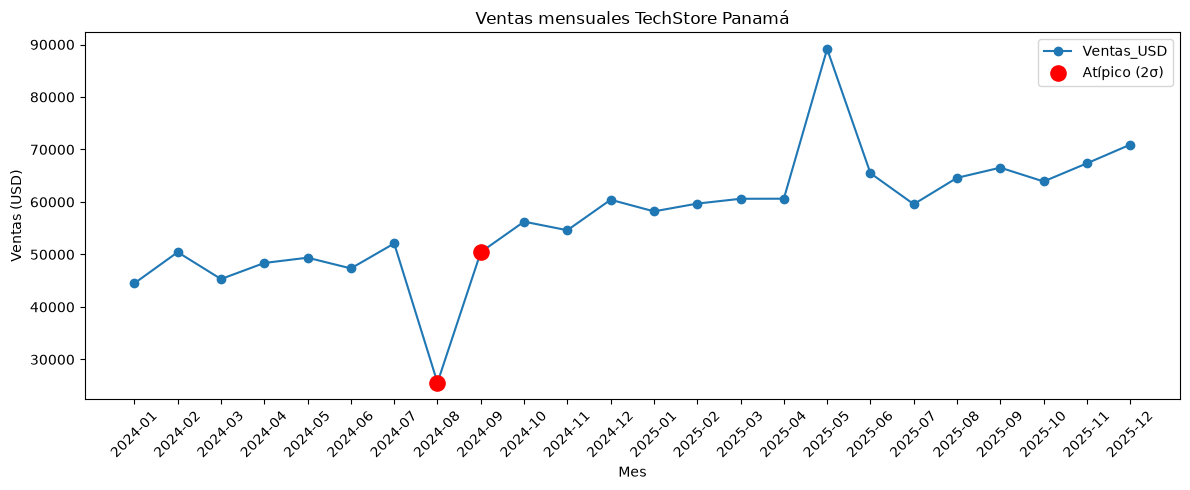

In [7]:
atipicos = ventas[ventas['atipico']]

plt.figure(figsize=(12, 5))
plt.plot(ventas['Mes'], ventas['Ventas_USD'], marker='o', label='Ventas_USD')
plt.scatter(atipicos['Mes'], atipicos['Ventas_USD'], color='red', s=120, zorder=3, label='Atípico (2σ)')
plt.title('Ventas mensuales TechStore Panamá')
plt.xlabel('Mes')
plt.ylabel('Ventas (USD)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

**Verificación**: los atípicos del enunciado son 2024-08 (caída por cierre temporal) y 2025-05 (pico por promoción).

La regla de 2σ sobre la variación porcentual marca **2024-08** (-50.9 %) y **2024-09** (+97.2 %), pero **no** 2025-05 (+47.3 %, por debajo del umbral de ±52.8 %).

- 2024-09 no es atípico en sí: es el rebote al nivel normal después de la caída, pero como la variación se calcula contra el mes anterior (que fue atípico), la derivada también se dispara.
- La caída de agosto infla tanto la desviación estándar que el pico de mayo 2025 queda por debajo del umbral.

Conclusión: el atributo derivado detecta cambios bruscos, no valores atípicos en sí; cada anomalía genera dos saltos (entrada y salida). Visualmente, en la serie original ambos meses (2024-08 y 2025-05) se distinguen con claridad.